In [ ]:
import marimo as mo
import pandas as pd
from scripts.extract_dataset import group_by_last_author
import matplotlib.pyplot as plt
import numpy as np

# Importing the ICLR OpenReview Dataset

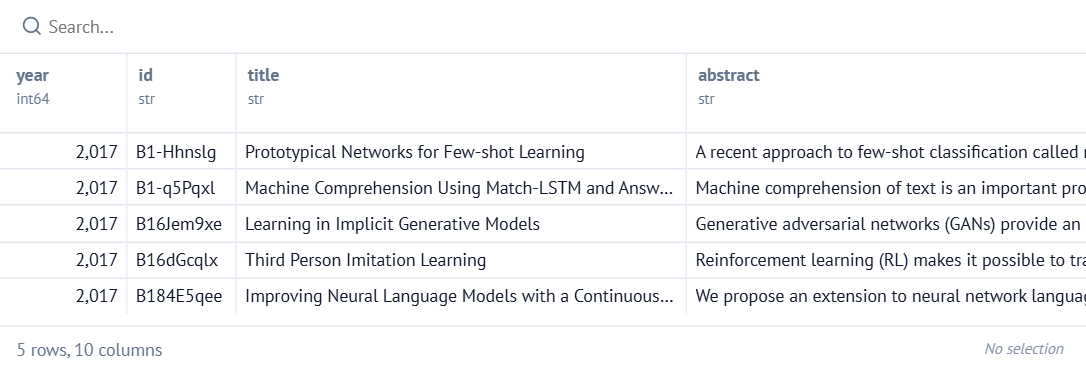

In [ ]:
iclr_df = pd.read_parquet("data/iclr26v1.parquet")
iclr_df.head()

# Group Papers by Principal Investigator (Last Listed Author)

Here we are assuming that the last author listed in `authors` is the Principal Investigators (PIs). We want to analyze the PIs because they have more publications than a new researcher.

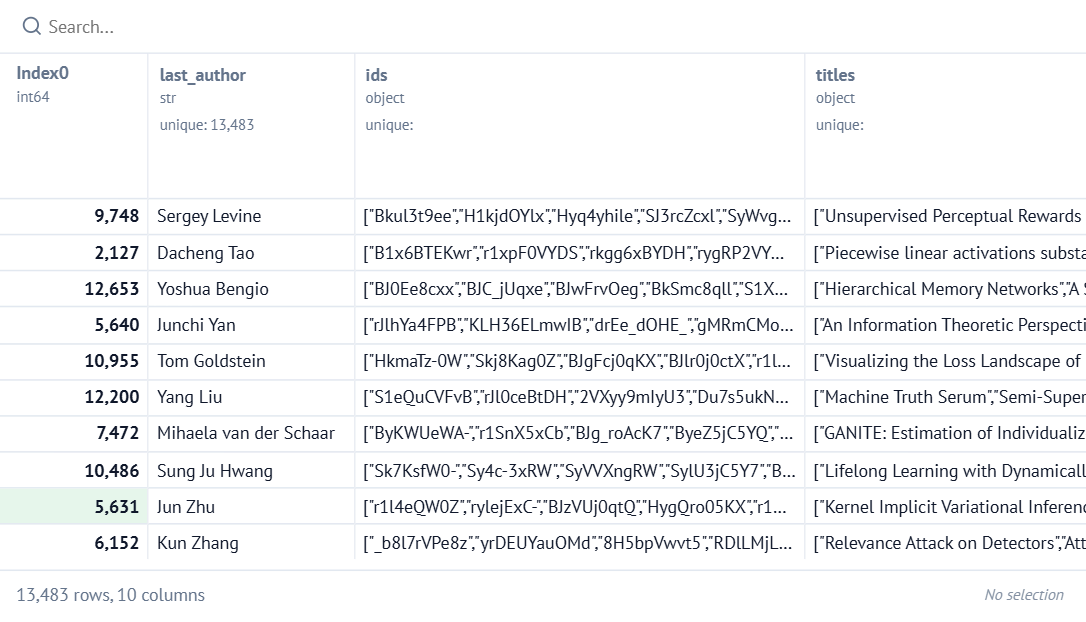

In [ ]:
pi_df = group_by_last_author(iclr_df)
pi_df.sort_values("num_papers", ascending=False)

In [ ]:
mo.md(r"""
# Initial Analysis
""")

<span class="markdown prose dark:prose-invert contents"><h1 id="initial-analysis">Initial Analysis</h1></span>

In [ ]:
mo.md(r"""
## Visualization: Complementary Cumulative Distribution Function (CCDF)
""")

<span class="markdown prose dark:prose-invert contents"><h2 id="visualization-complementary-cumulative-distribution-function-ccdf">Visualization: Complementary Cumulative Distribution Function (CCDF)</h2></span>

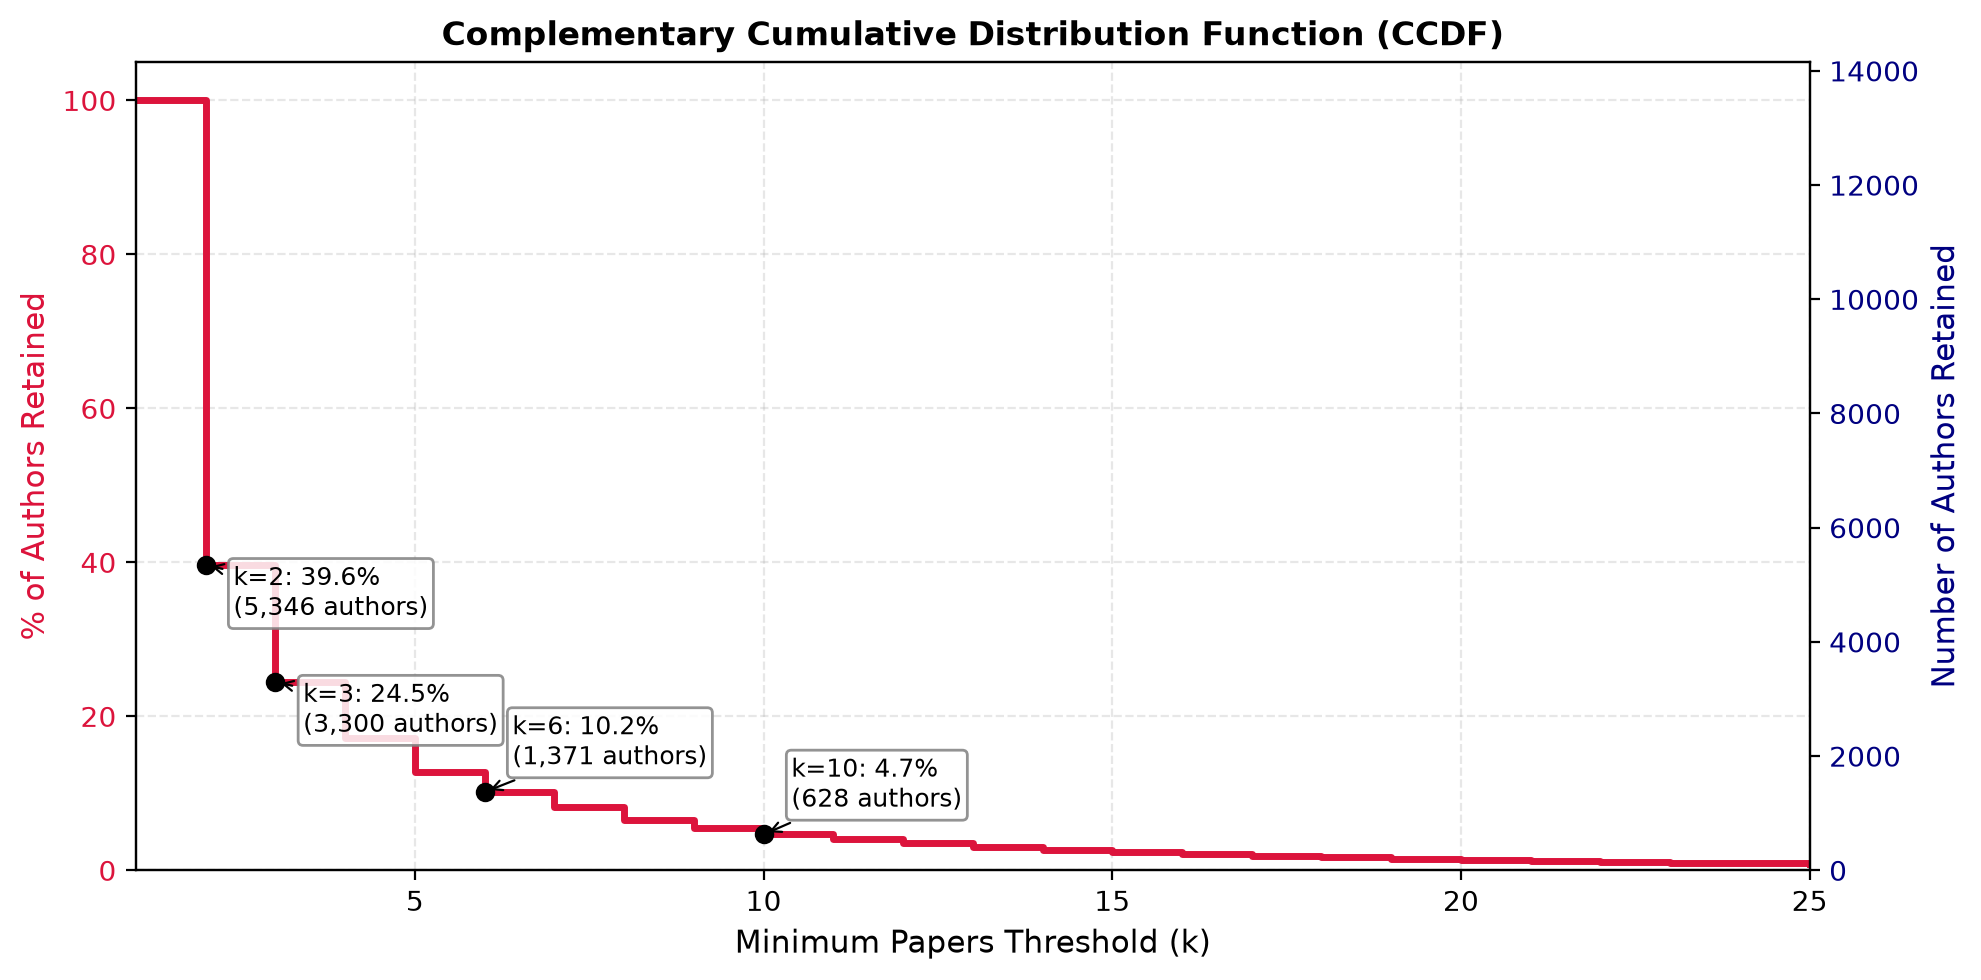

In [ ]:
paper_counts = pi_df["num_papers"].values
n_total = len(paper_counts)

k_values = np.arange(1, 26)
retention_pct = np.array([(paper_counts >= k).mean() * 100 for k in k_values])

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.step(k_values, retention_pct, where="post", color="crimson", linewidth=2.5)
ax1.set_xlabel("Minimum Papers Threshold (k)", fontsize=11)
ax1.set_ylabel("% of Authors Retained", color="crimson", fontsize=11)
ax1.tick_params(axis="y", labelcolor="crimson")
ax1.set_xlim(1, 25)
ax1.set_ylim(0, 105)
ax1.grid(True, linestyle="--", alpha=0.3)


ax2 = ax1.twinx()
ax2.set_ylabel("Number of Authors Retained", color="navy", fontsize=11)
ax2.set_ylim(0, n_total * 1.05)
ax2.tick_params(axis="y", labelcolor="navy")

for k in [2, 3, 6, 10]:
    pct = (paper_counts >= k).mean() * 100
    cnt = (paper_counts >= k).sum()
    ax1.plot(k, pct, marker="o", markersize=6, color="black", zorder=5)
    ax1.annotate(
        f"k={k}: {pct:.1f}%\n({cnt:,} authors)",
        (k, pct),
        textcoords="offset points",
        xytext=(10, -18 if k in [2, 3] else 10),
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="gray", alpha=0.85),
        arrowprops=dict(arrowstyle="->", lw=0.8, color="black")
    )

plt.title("Complementary Cumulative Distribution Function (CCDF)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
mo.md(r"""
For this inital analysis, we have decided to look at last listed authors who are part of 5 papers or more. This is because we want to study researchers who published more than 1 paper. These are the authors who decided to stay within a field and to change fields.

However, there are researchers who do not collaborate with other people. This is included in our dataset. Are these independent researchers considered PIs? Let's look at the number of independent researchers in the dataset.
""")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">For this inital analysis, we have decided to look at last listed authors who are part of 5 papers or more. This is because we want to study researchers who published more than 1 paper. These are the authors who decided to stay within a field and to change fields.</span>
<span class="paragraph">However, there are researchers who do not collaborate with other people. This is included in our dataset. Are these independent researchers considered PIs? Let's look at the number of independent researchers in the dataset.</span></span>

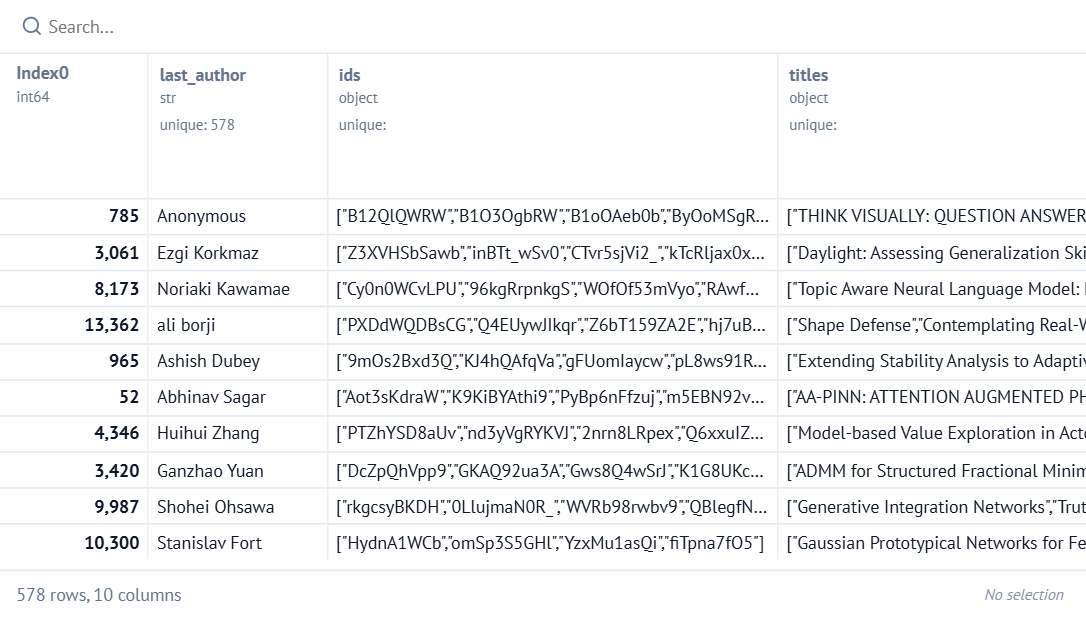

In [ ]:
solo_authors = pi_df[pi_df["collaborators"].apply(lambda collabs: all(len(c) == 0 for c in collabs))]
solo_authors.sort_values("num_papers", ascending=False)

In [ ]:
print(f"Authors with only solo papers: {len(solo_authors)}")
print(f"Average number of publications for solo-only authors: {solo_authors['num_papers'].mean():.2f}")

Authors with only solo papers: 578
Average number of publications for solo-only authors: 1.24


In [ ]:
mo.md(r"""
Here we will eliminate papers who list "Anonymous" as the author. 
""")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Here we will eliminate papers who list "Anonymous" as the author. </span></span>

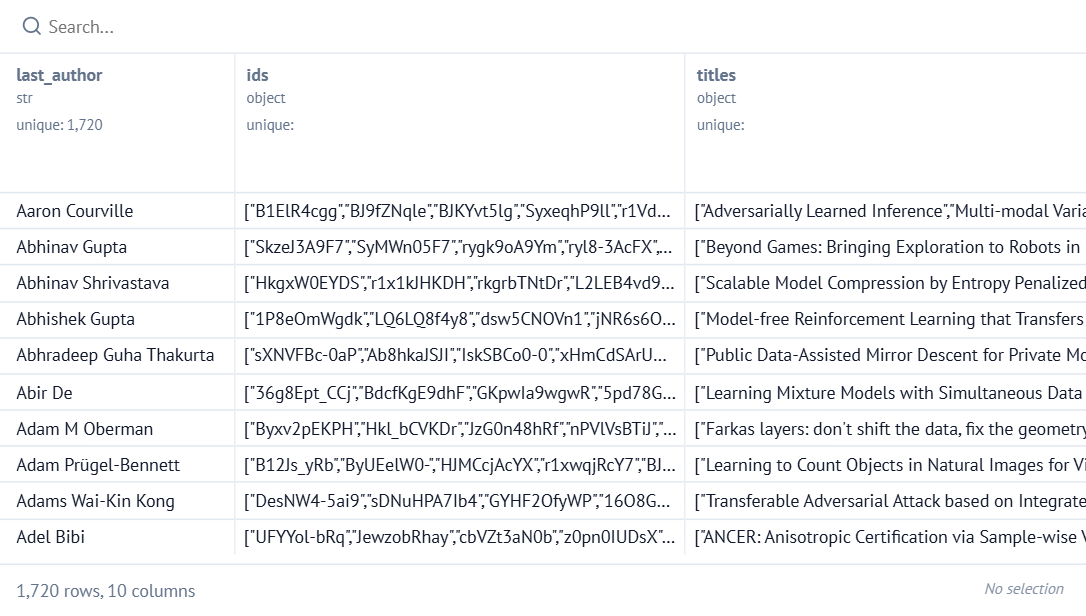

In [ ]:
threshold = 5
df = pi_df[(pi_df["num_papers"] >= threshold) & (pi_df["last_author"] != "Anonymous")].reset_index(drop=True)
df

## Distribution of Papers per Author

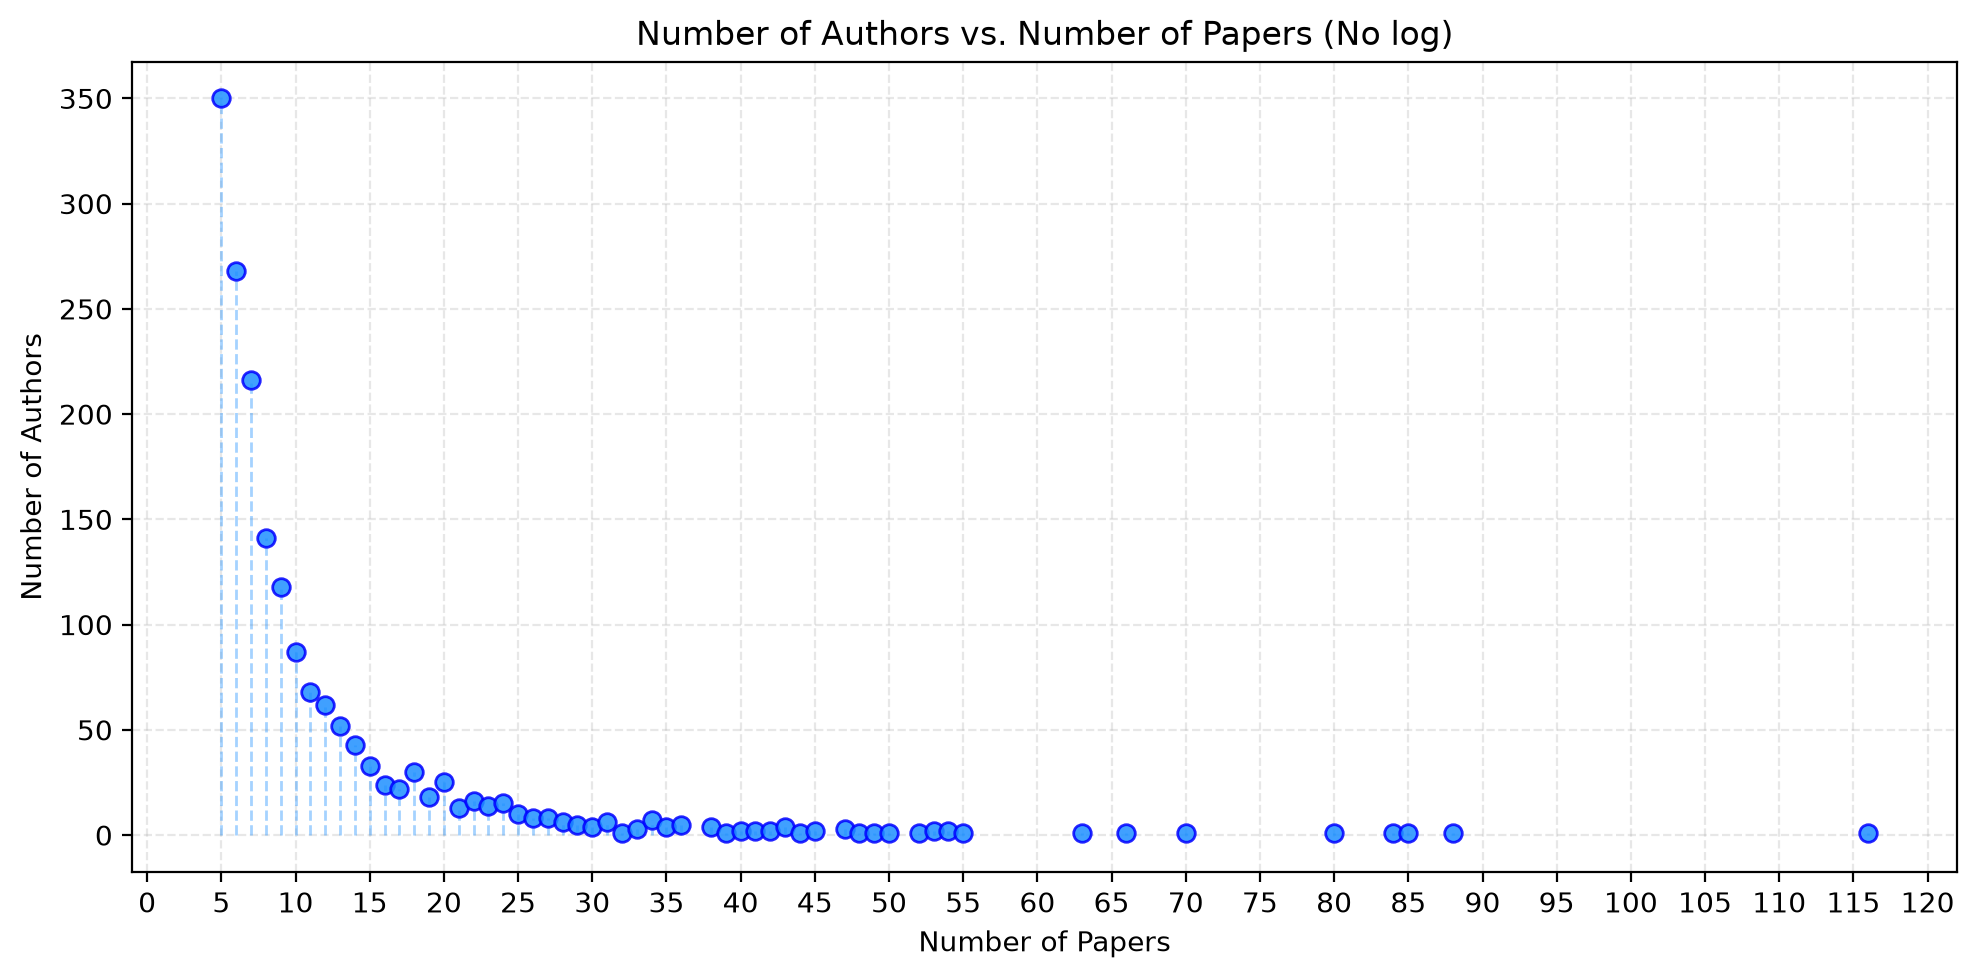

In [ ]:
paper_freq = df["num_papers"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.vlines(
    x=paper_freq.index,
    ymin=0,
    ymax=paper_freq.values,
    color="dodgerblue",
    linestyle="--",
    alpha=0.4,
    linewidth=1,
)
plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)
plt.xticks(range(0, 125, 5))
plt.xlim(left=-1, right=122)
plt.title("Number of Authors vs. Number of Papers (No log)")
plt.xlabel("Number of Papers")
plt.ylabel("Number of Authors")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.gca()

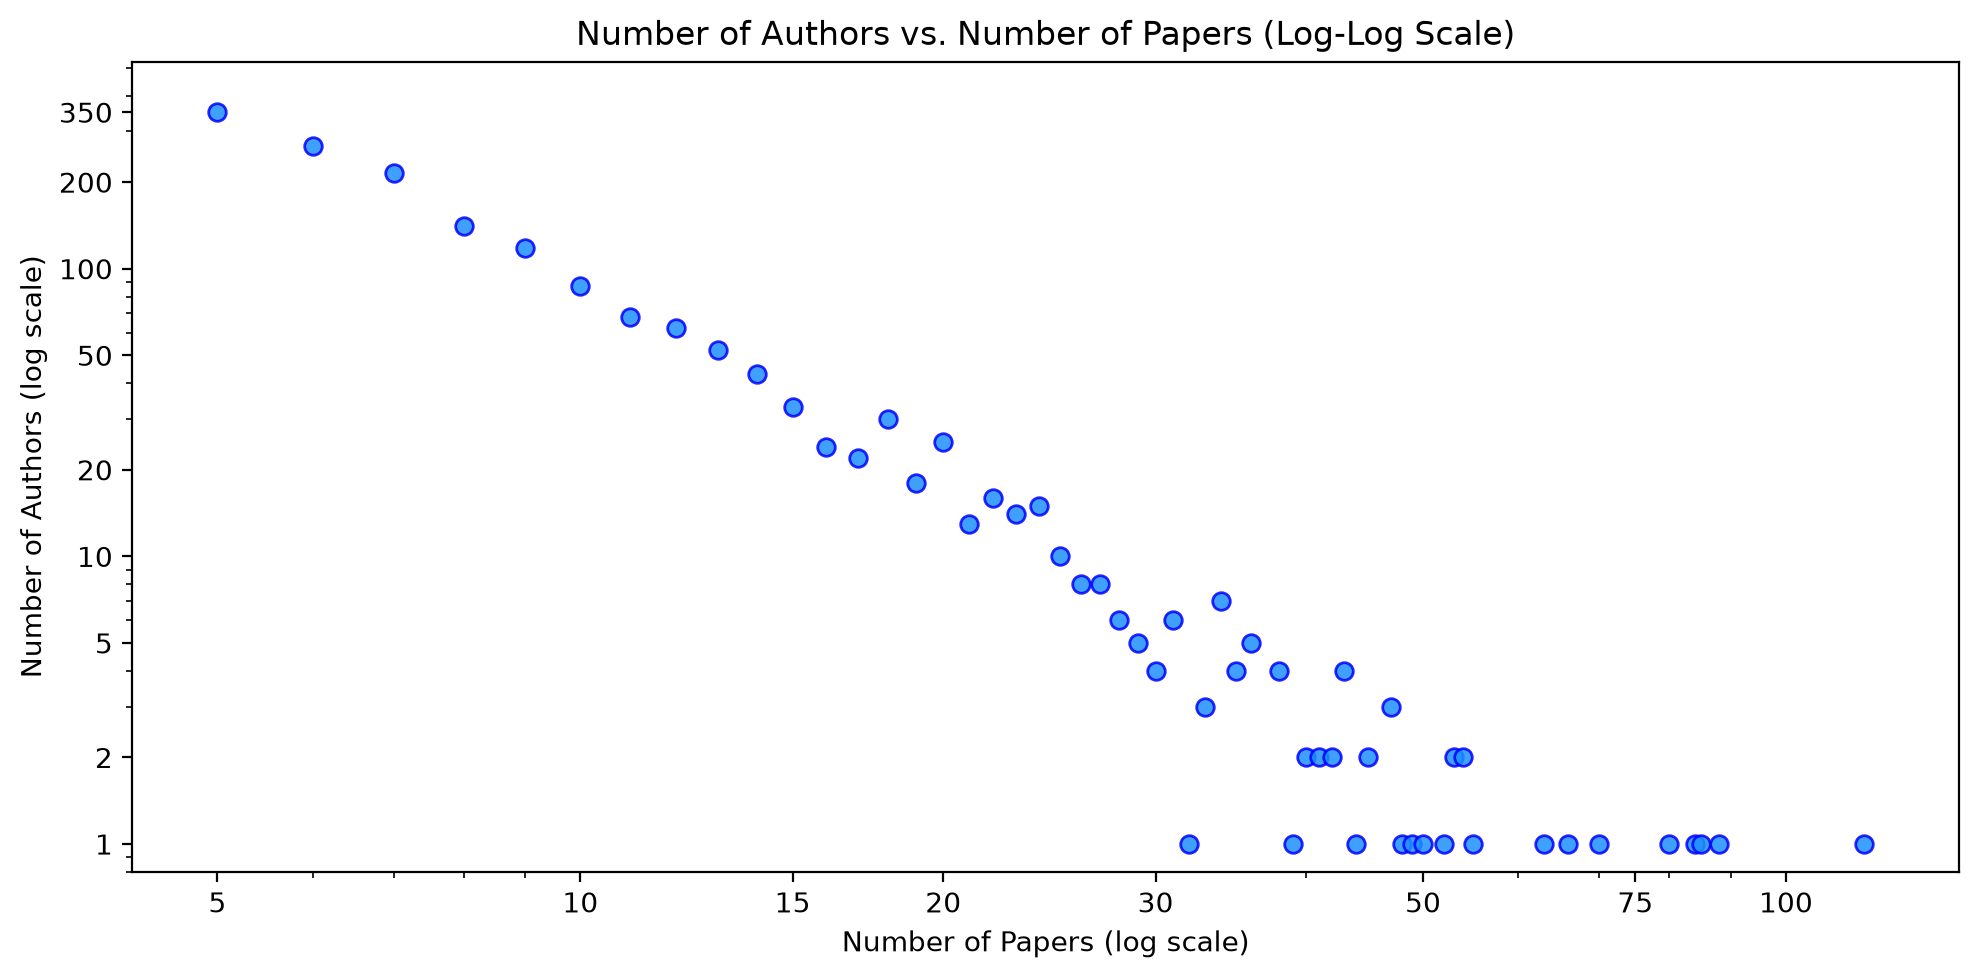

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)
plt.xscale("log")
plt.yscale("log")

plt.xlim(left=threshold * 0.85, right=paper_freq.index.max() * 1.2)
plt.ylim(bottom=0.8, top=paper_freq.values.max() * 1.5)

x_ticks = [5, 10, 15, 20, 30, 50, 75, 100]
plt.xticks(x_ticks, x_ticks)

y_ticks = [1, 2, 5, 10, 20, 50, 100, 200, 350]
plt.yticks(y_ticks, y_ticks)

plt.title("Number of Authors vs. Number of Papers (Log-Log Scale)")
plt.xlabel("Number of Papers (log scale)")
plt.ylabel("Number of Authors (log scale)")
plt.tight_layout()
plt.gca()